
# Notebook 12: Train, Validation & Test Data

## Objective
Learn how to split datasets correctly and prevent data leakage
during machine learning model development.

## Learning Outcomes
- Understand training, validation, and test datasets.
- Apply train-test and train-validation-test splitting.
- Understand random_state and stratified sampling.
- Understand temporal splitting for time-dependent data.
- Identify data leakage.
- Demonstrate correct and incorrect preprocessing workflows.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from sklearn.datasets import make_classification

X_array, y_array = make_classification(
    n_samples=1000,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    weights=[0.80, 0.20],
    random_state=42
)

feature_names = [f"Feature_{i}" for i in range(1, 7)]

X = pd.DataFrame(X_array, columns=feature_names)
y = pd.Series(y_array, name="Target")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
print("\nTarget distribution:")
display(y.value_counts().sort_index())

Features shape: (1000, 6)
Target shape: (1000,)


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6
0,0.351385,2.182377,-0.255875,-0.388255,0.892724,-0.868436
1,-1.800301,0.169075,1.640729,-1.884878,2.475151,0.236966
2,-0.662567,-0.965904,-1.349986,-0.151772,0.034064,-1.147303
3,0.071325,1.530983,-0.103807,-0.220439,0.841334,1.106722
4,-0.251711,-1.705038,-1.373556,0.320075,-0.823443,-0.662904



Target distribution:


Target
0    798
1    202
Name: count, dtype: int64


## 1. Training, Validation, and Test Datasets

### Training Dataset
Used to fit the model and learn patterns from the data.

### Validation Dataset
Used to compare models, tune hyperparameters, and select
appropriate modeling decisions.

### Test Dataset
Used for final evaluation after model development is complete.

The test set should not influence feature selection, preprocessing
choices, or hyperparameter tuning. Otherwise, the reported
performance may be overly optimistic.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (800, 6)
Testing features: (200, 6)
Training targets: (800,)
Testing targets: (200,)


In [4]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("Total rows:", len(X_train) + len(X_test))
print("Original rows:", len(X))

assert len(X_train) + len(X_test) == len(X)
assert X_train.index.intersection(X_test.index).empty

print("Split verification passed!")

Training rows: 800
Testing rows: 200
Total rows: 1000
Original rows: 1000
Split verification passed!


In [5]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining percentage:", round(len(X_train) / len(X) * 100, 1))
print("Validation percentage:", round(len(X_val) / len(X) * 100, 1))
print("Test percentage:", round(len(X_test) / len(X) * 100, 1))

Training set: (600, 6)
Validation set: (200, 6)
Test set: (200, 6)

Training percentage: 60.0
Validation percentage: 20.0
Test percentage: 20.0


In [6]:
X_train_a, X_test_a = train_test_split(
    X,
    test_size=0.20,
    random_state=42
)

X_train_b, X_test_b = train_test_split(
    X,
    test_size=0.20,
    random_state=42
)

print("Same training split:",
      X_train_a.equals(X_train_b))

print("Same testing split:",
      X_test_a.equals(X_test_b))

Same training split: True
Same testing split: True



## 2. What Is random_state?

random_state controls the randomness used when splitting data.

Using the same random_state and the same input data makes the
split reproducible.

This helps with debugging, comparing models, and repeating
experiments.

A random state does not guarantee that a model will perform well.
It simply makes the randomized operation repeatable.


In [7]:
X_train_strat, X_test_strat, y_train_strat, y_test_strat = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print("Original target proportions:")
display(y.value_counts(normalize=True).sort_index().round(3))

print("\nTraining target proportions:")
display(
    y_train_strat.value_counts(normalize=True).sort_index().round(3)
)

print("\nTest target proportions:")
display(
    y_test_strat.value_counts(normalize=True).sort_index().round(3)
)

Original target proportions:


Target
0    0.798
1    0.202
Name: proportion, dtype: float64


Training target proportions:


Target
0    0.798
1    0.202
Name: proportion, dtype: float64


Test target proportions:


Target
0    0.8
1    0.2
Name: proportion, dtype: float64


## 3. What Is Data Leakage?

Data leakage occurs when information that would not legitimately
be available at prediction time influences model training or
model selection.

Examples:
- Scaling the complete dataset before splitting.
- Filling missing values using statistics from the full dataset.
- Selecting features using the complete dataset before splitting.
- Using future information to predict past events.
- Tuning a model repeatedly against the final test set.

Leakage can make evaluation results look better than the model's
real-world performance.

The correct approach is to split the data first, fit preprocessing
on training data only, and apply the fitted transformations to
validation and test data.


In [8]:
# INCORRECT: Do not use this workflow in a real ML project.

incorrect_scaler = StandardScaler()

X_scaled_incorrect = pd.DataFrame(
    incorrect_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

X_train_bad, X_test_bad, y_train_bad, y_test_bad = train_test_split(
    X_scaled_incorrect,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Incorrect workflow completed for demonstration only.")
print("Scaler mean calculated from all rows:")
print(pd.Series(
    incorrect_scaler.mean_,
    index=X.columns
).round(3))

Incorrect workflow completed for demonstration only.
Scaler mean calculated from all rows:
Feature_1   -0.843
Feature_2    0.035
Feature_3    0.004
Feature_4   -0.814
Feature_5    1.092
Feature_6    0.043
dtype: float64


In [9]:
# CORRECT: Split first, then fit preprocessing on training data only.

X_train_good, X_test_good, y_train_good, y_test_good = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

correct_scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    correct_scaler.fit_transform(X_train_good),
    columns=X.columns,
    index=X_train_good.index
)

X_test_scaled = pd.DataFrame(
    correct_scaler.transform(X_test_good),
    columns=X.columns,
    index=X_test_good.index
)

print("Training feature means after scaling:")
display(X_train_scaled.mean().round(3))

print("\nTest feature means after applying training scaler:")
display(X_test_scaled.mean().round(3))

print("\nCorrect preprocessing completed!")

Training feature means after scaling:


Feature_1   -0.0
Feature_2    0.0
Feature_3    0.0
Feature_4    0.0
Feature_5   -0.0
Feature_6    0.0
dtype: float64


Test feature means after applying training scaler:


Feature_1   -0.154
Feature_2   -0.001
Feature_3    0.071
Feature_4   -0.126
Feature_5    0.130
Feature_6   -0.009
dtype: float64


Correct preprocessing completed!


In [10]:
X_train_pipe, X_test_pipe, y_train_pipe, y_test_pipe = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

pipeline.fit(X_train_pipe, y_train_pipe)

test_predictions = pipeline.predict(X_test_pipe)

print("Test accuracy:", round(
    accuracy_score(y_test_pipe, test_predictions), 3
))

Test accuracy: 0.81


In [11]:
df_time = pd.DataFrame({
    "Date": pd.date_range("2026-01-01", periods=20, freq="D"),
    "Sales": np.arange(100, 300, 10),
    "Advertising": np.arange(10, 30)
})

df_time = df_time.sort_values("Date").reset_index(drop=True)

train_end = int(len(df_time) * 0.60)
val_end = int(len(df_time) * 0.80)

train_time = df_time.iloc[:train_end].copy()
val_time = df_time.iloc[train_end:val_end].copy()
test_time = df_time.iloc[val_end:].copy()

print("Training dates:")
print(train_time["Date"].min(), "to", train_time["Date"].max())

print("\nValidation dates:")
print(val_time["Date"].min(), "to", val_time["Date"].max())

print("\nTest dates:")
print(test_time["Date"].min(), "to", test_time["Date"].max())

Training dates:
2026-01-01 00:00:00 to 2026-01-12 00:00:00

Validation dates:
2026-01-13 00:00:00 to 2026-01-16 00:00:00

Test dates:
2026-01-17 00:00:00 to 2026-01-20 00:00:00


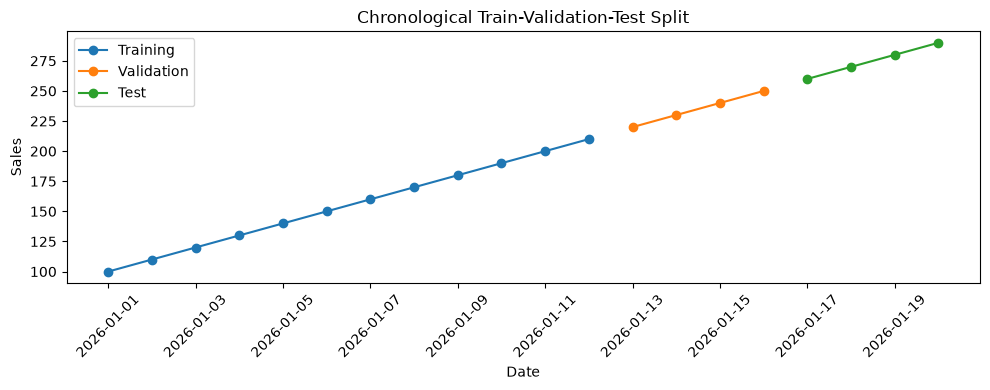

In [12]:
plt.figure(figsize=(10, 4))

plt.plot(
    train_time["Date"],
    train_time["Sales"],
    marker="o",
    label="Training"
)

plt.plot(
    val_time["Date"],
    val_time["Sales"],
    marker="o",
    label="Validation"
)

plt.plot(
    test_time["Date"],
    test_time["Sales"],
    marker="o",
    label="Test"
)

plt.title("Chronological Train-Validation-Test Split")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 4. Why Fit Preprocessing Only on Training Data?

Preprocessing methods learn information from the data.

Examples:
- Mean and median imputation learn replacement values.
- StandardScaler learns means and standard deviations.
- MinMaxScaler learns minimum and maximum values.
- Feature selection learns which features appear useful.
- Target encoding learns statistics from the target.

If these methods are fitted on the complete dataset before
splitting, information from validation or test observations can
influence model development.

Correct workflow:

1. Split data into training, validation, and test sets.
2. Fit preprocessing methods on training data only.
3. Transform training data using the fitted methods.
4. Transform validation and test data using those same methods.
5. Use validation data for model selection and tuning.
6. Evaluate the final model on the untouched test set.



## 5. Summary

| Method | Appropriate use |
|---|---|
| Train-test split | Basic model development and final evaluation |
| Train-validation-test split | Model tuning plus final evaluation |
| random_state | Reproducible randomized splits |
| Stratified sampling | Preserving class proportions in classification |
| Temporal splitting | Time-dependent prediction tasks |
| Preprocessing pipeline | Consistent transformations and reduced leakage risk |

The split strategy should reflect how the model will be used in
practice. For example, time-based prediction usually requires
chronological evaluation rather than a random split.



## Conclusion

In this notebook, I learned the purpose of training, validation,
and test datasets and practiced train-test and train-validation-test
splitting.

I explored random_state, stratified sampling, and temporal splitting.

I demonstrated an incorrect workflow that fits a scaler before
splitting and a correct workflow that fits preprocessing only on
training data.

I also used a scikit-learn pipeline to combine imputation,
standardization, and model training.

Correct data splitting and leakage prevention are essential for
obtaining reliable estimates of machine learning performance.
